
================ ERI ABLATION STUDY (MODEL-WISE) ================

            Model  Accuracy_Stability_Mean  LMOS_Stability_Mean  ERI (Full)  ERI w/o Accuracy  ERI w/o LMOS
       Custom CNN                   0.9563               0.7798     0.86805           0.38990       0.47815
      Densenet121                   0.9808               0.8978     0.93930           0.44890       0.49040
InceptionResnetV2                   0.9811               0.8736     0.92735           0.43680       0.49055
     Inception V3                   0.9795               0.7858     0.88265           0.39290       0.48975
     MobileNet V2                   0.9758               0.8541     0.91495           0.42705       0.48790
         ResNet50                   0.8944               0.8960     0.89520           0.44800       0.44720
            VGG16                   0.9644               0.8880     0.92620           0.44400       0.48220
         Xception                   0.9901               0.9478     

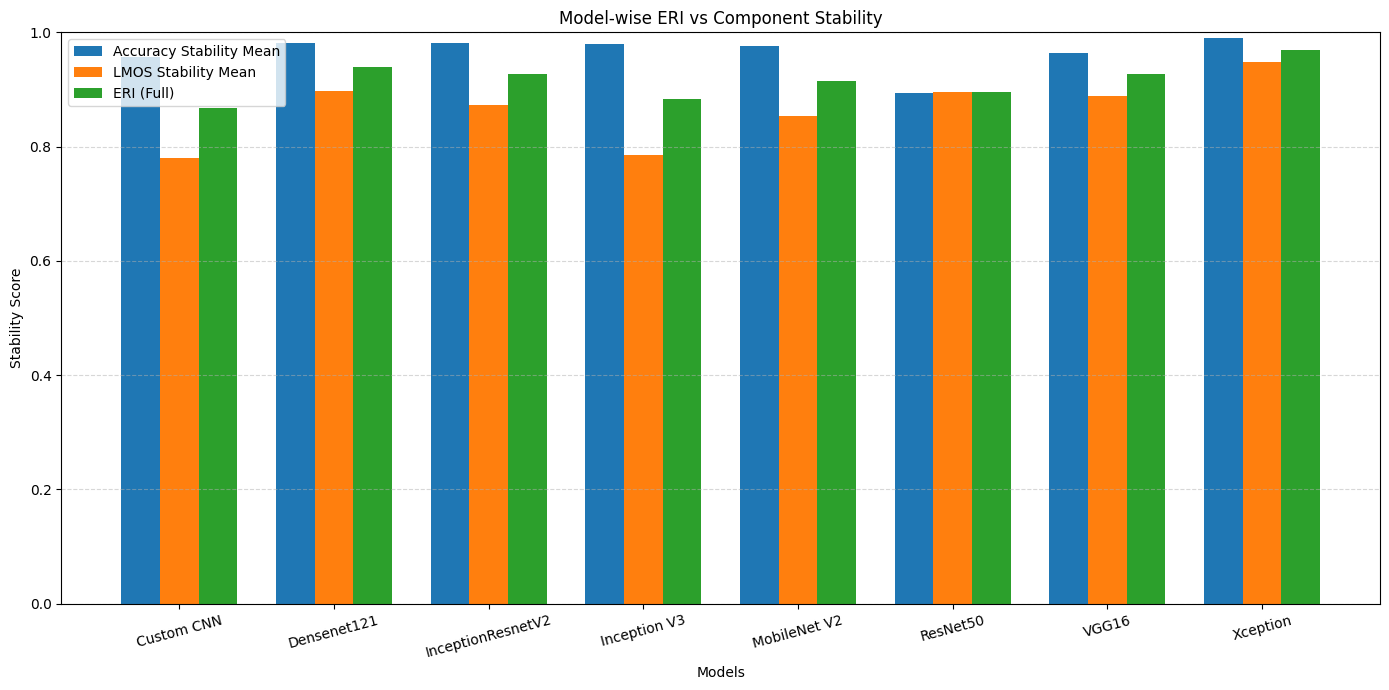

Saved: eri_modelwise_components.png


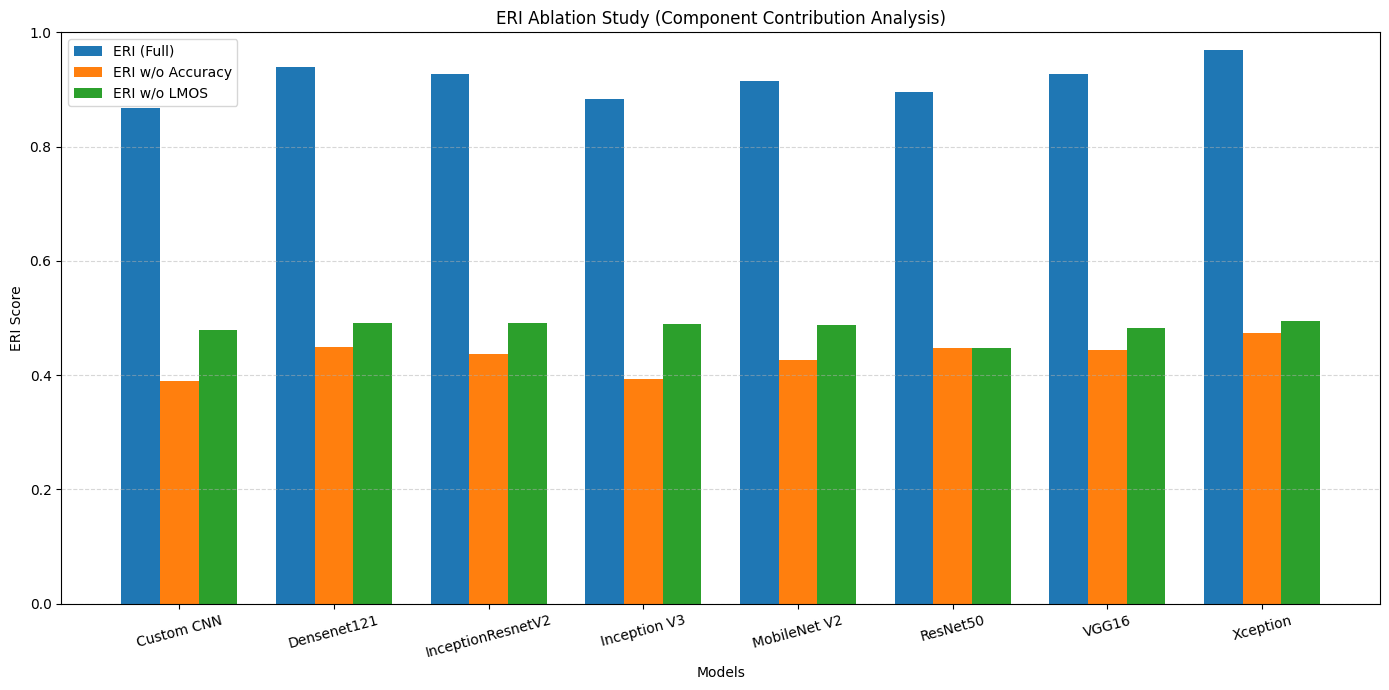

Saved: eri_modelwise_ablation.png
Saved: eri_modelwise_ablation.csv


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ====================================================
# MODEL NAMES
# ====================================================

models = [
    "Custom CNN",
    "Densenet121",
    "InceptionResnetV2",
    "Inception V3",
    "MobileNet V2",
    "ResNet50",
    "VGG16",
    "Xception"
    
]



np.random.seed(42)

accuracy_stability_mean = [0.9563, 0.9808, 0.9811, 0.9795, 0.9758, 0.8944, 0.9644, 0.9901]
lmos_stability_mean     = [0.7798, 0.8978, 0.8736, 0.7858, 0.8541, 0.8960, 0.8880, 0.9478]

# ====================================================
# ERI COMPUTATION
# ====================================================

eri_full = [(a + l) / 2 for a, l in zip(accuracy_stability_mean, lmos_stability_mean)]
eri_no_accuracy = [l / 2 for l in lmos_stability_mean]
eri_no_lmos     = [a / 2 for a in accuracy_stability_mean]

# ====================================================
# TABLE WITH ABLATION
# ====================================================

df = pd.DataFrame({
    "Model": models,
    "Accuracy_Stability_Mean": accuracy_stability_mean,
    "LMOS_Stability_Mean": lmos_stability_mean,
    "ERI (Full)": eri_full,
    "ERI w/o Accuracy": eri_no_accuracy,
    "ERI w/o LMOS": eri_no_lmos
})

# ====================================================
# PRINT TABLE
# ====================================================

print("\n================ ERI ABLATION STUDY (MODEL-WISE) ================\n")
print(df.to_string(index=False))

# ====================================================
# PLOT 1: COMPONENT COMPARISON
# ====================================================

x = np.arange(len(models))
width = 0.25

plt.figure(figsize=(14,7))

plt.bar(x - width, accuracy_stability_mean, width, label="Accuracy Stability Mean")
plt.bar(x, lmos_stability_mean, width, label="LMOS Stability Mean")
plt.bar(x + width, eri_full, width, label="ERI (Full)")

plt.xticks(x, models, rotation=15)
plt.ylabel("Stability Score")
plt.xlabel("Models")
plt.title("Model-wise ERI vs Component Stability")

plt.ylim(0.0, 1.0)

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()

plt.savefig("eri_modelwise_components.png", dpi=600, bbox_inches='tight')
plt.show()

print("Saved: eri_modelwise_components.png")

# ====================================================
# PLOT 2: ABLATION VISUALIZATION
# ====================================================

plt.figure(figsize=(14,7))

plt.bar(x - width, eri_full, width, label="ERI (Full)")
plt.bar(x, eri_no_accuracy, width, label="ERI w/o Accuracy")
plt.bar(x + width, eri_no_lmos, width, label="ERI w/o LMOS")

plt.xticks(x, models, rotation=15)
plt.ylabel("ERI Score")
plt.xlabel("Models")
plt.title("ERI Ablation Study (Component Contribution Analysis)")

plt.ylim(0.0, 1.0)

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()

plt.savefig("eri_modelwise_ablation.png", dpi=600, bbox_inches='tight')
plt.show()

print("Saved: eri_modelwise_ablation.png")

# ====================================================
# SAVE TABLE
# ====================================================

df.to_csv("eri_modelwise_ablation.csv", index=False)

print("Saved: eri_modelwise_ablation.csv")